In [5]:
import scipy.io as sio
import os
import numpy as np

# Define directory path
data_dir = "/Users/borjan/code/healthy-sleep-project/code/results/ssdi_results/time"

# Define conditions and participants
conditions = ['N1', 'N2', 'N3', 'W_', 'R_']
participants = [f"{i:02d}" for i in range(1, 30)]  # Participants 01 to 29
macros = range(2, 10)  # Macroscopic sizes 2 to 9

# Initialize structures to store gopto, beta_*, and dopto_* matrices
opt_similarity_matrices = {cond: {part: {} for part in participants} for cond in conditions}
beta_matrices = {cond: {part: {} for part in participants} for cond in conditions}
dopto_matrices = {cond: {part: {} for part in participants} for cond in conditions}

# Load files and extract gopto, beta_*, and dopto_*
for participant in participants:
    for condition in conditions:
        # Construct the filename
        filename = f"EPCTL{participant}_{condition}_ssdi_time_domain_results.mat"
        filepath = os.path.join(data_dir, filename)
        
        # Load the MATLAB file
        mat_data = sio.loadmat(filepath)

        # Extract from the 'results' structure
        results = mat_data['results']
        
        for m in macros:
            # Define the keys for gopto, beta, and dopto
            opt_key = f'gopto_m{m}'   # Key for optimization (gopto)
            beta_key = f'beta_m{m}'   # Key for beta values
            dopto_key = f'dopto_m{m}' # Key for dopto values

            # Extract gopto (optimization similarity matrices)
            if opt_key in results.dtype.names:
                opt_similarity_matrices[condition][participant][m] = results[opt_key][0, 0]
            else:
                print(f"gopto for macro size {m} not found for {participant}, {condition}")

            # Extract beta_* values
            if beta_key in results.dtype.names:
                beta_matrices[condition][participant][m] = results[beta_key][0, 0]
            else:
                print(f"beta_* for macro size {m} not found for {participant}, {condition}")

            # Extract dopto_* values
            if dopto_key in results.dtype.names:
                dopto_matrices[condition][participant][m] = results[dopto_key][0, 0]
            else:
                print(f"dopto_* for macro size {m} not found for {participant}, {condition}")

# Now we have gopto, beta_*, and dopto_* matrices stored


In [6]:
# Example: Check for participant 01, condition W_, 2-macro
example_participant = '01'
example_condition = 'W_'
example_macro = 2

# Check Optimization Matrix (gopto)
opt_matrix = opt_similarity_matrices[example_condition][example_participant][example_macro]
print(f"Optimization matrix for participant {example_participant}, condition {example_condition}, {example_macro}-macro:")
print(opt_matrix)
print(f"Shape of optimization matrix: {opt_matrix.shape if opt_matrix is not None else 'None'}")

# Check Beta Matrix (beta_*)
beta_matrix = beta_matrices[example_condition][example_participant][example_macro]
print(f"\nBeta matrix for participant {example_participant}, condition {example_condition}, {example_macro}-macro:")
print(beta_matrix)
print(f"Shape of beta matrix: {beta_matrix.shape if beta_matrix is not None else 'None'}")

# Check Dopto Value (dopto_*)
dopto_vector = dopto_matrices[example_condition][example_participant][example_macro]
print(f"\nDopto value for participant {example_participant}, condition {example_condition}, {example_macro}-macro:")
print(dopto_vector)
print(f"Shape of beta matrix: {dopto_vector.shape if dopto_vector is not None else 'None'}")



Optimization matrix for participant 01, condition W_, 2-macro:
[[0.         0.76321085 0.64051429 ... 0.9893447  0.99505966 0.96124982]
 [0.76321085 0.         0.7287484  ... 0.97708636 0.98357544 0.95066885]
 [0.64051429 0.7287484  0.         ... 0.98380352 0.99222186 0.98487781]
 ...
 [0.9893447  0.97708636 0.98380352 ... 0.         0.93904219 0.9310577 ]
 [0.99505966 0.98357544 0.99222186 ... 0.93904219 0.         0.94061162]
 [0.96124982 0.95066885 0.98487781 ... 0.9310577  0.94061162 0.        ]]
Shape of optimization matrix: (100, 100)

Beta matrix for participant 01, condition W_, 2-macro:
[[6.77316108e-05 3.09852009e-03 3.61351806e-05 ... 1.11554768e-02
  6.61225165e-02 1.97167242e-04]
 [3.66289054e-03 1.00418984e-02 2.38635886e-03 ... 1.18493125e-02
  1.26426214e-02 9.83556462e-03]
 [3.27564452e-03 9.78398076e-04 1.86904357e-03 ... 4.73889716e-03
  3.05576221e-02 2.17259057e-02]
 ...
 [3.07704593e-01 3.39682362e-01 2.90254791e-01 ... 1.74089564e-02
  2.24922536e-02 8.72703906e

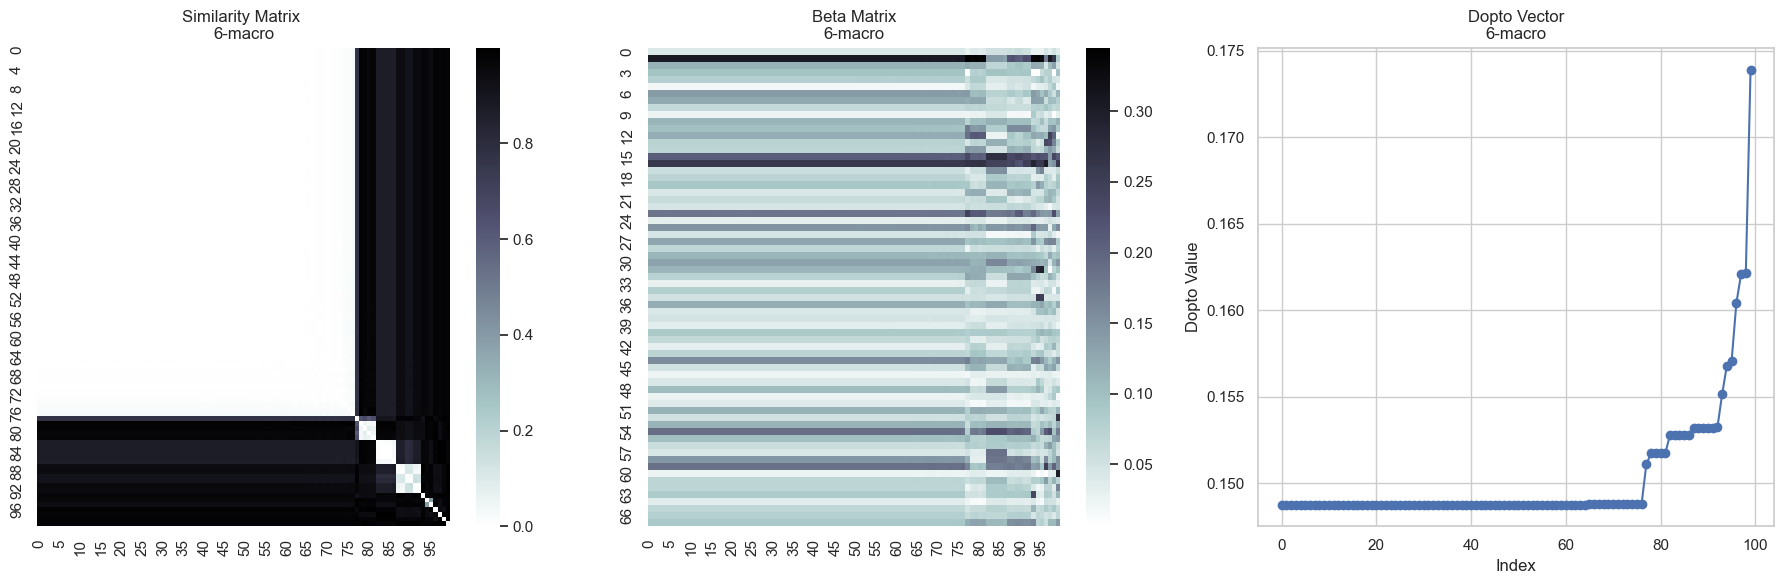

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Example: Check for participant 01, condition W_, 2-macro
example_participant = '15'
example_condition = 'R_'
example_macro = 6

# Extract the matrices and vector
opt_matrix = opt_similarity_matrices[example_condition][example_participant][example_macro]
beta_matrix = beta_matrices[example_condition][example_participant][example_macro]
dopto_vector = dopto_matrices[example_condition][example_participant][example_macro]

# Create a figure with subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Plot the optimization (gopto) similarity matrix
sns.heatmap(opt_matrix, cmap='bone_r', ax=axes[0])
axes[0].set_title(f'Similarity Matrix \n{example_macro}-macro')

# Plot the beta matrix
sns.heatmap(beta_matrix, cmap='bone_r', ax=axes[1])
axes[1].set_title(f'Beta Matrix\n{example_macro}-macro')

# Plot the dopto vector as a line plot
axes[2].plot(dopto_vector.flatten(), marker='o')
axes[2].set_title(f'Dopto Vector\n{example_macro}-macro')
axes[2].set_xlabel('Index')
axes[2].set_ylabel('Dopto Value')

# Adjust the layout
plt.tight_layout()
plt.show()


In [8]:
import os
import numpy as np

# Define the directory where the results will be saved
save_dir = "/Users/borjan/code/healthy-sleep-project/code/ssdi_analysis/data/"

# Check if the directory exists, if not, create it
if not os.path.exists(save_dir):
    os.makedirs(save_dir)
    print(f"Directory {save_dir} created.")

# Save the data structures in the specified directory
np.savez(os.path.join(save_dir, 'opt_similarity_matrices.npz'), **opt_similarity_matrices)
np.savez(os.path.join(save_dir, 'beta_matrices.npz'), **beta_matrices)
np.savez(os.path.join(save_dir, 'dopto_vectors.npz'), **dopto_matrices)

print(f"Data saved successfully in {save_dir}")

# To load the data later:
# loaded_opt = np.load(os.path.join(save_dir, 'opt_similarity_matrices.npz'), allow_pickle=True)
# loaded_beta = np.load(os.path.join(save_dir, 'beta_matrices.npz'), allow_pickle=True)
# loaded_dopto = np.load(os.path.join(save_dir, 'dopto_vectors.npz'), allow_pickle=True)


Data saved successfully in /Users/borjan/code/healthy-sleep-project/code/ssdi_analysis/data/


In [10]:
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
import numpy as np

# Define the conditions to compare
condition_1 = 'W_'
condition_2 = 'N1'

# Macroscopic sizes
macros = range(2, 10)

# Initialize a list to store p-values for each macroscopic size
p_values = []

# Perform the grouped MWU test for each macroscopic size
for macro_size in macros:
    # Collate dopto vectors for condition_1 (e.g., W_) across all participants
    group_1 = [dopto_matrices[condition_1][participant][macro_size] for participant in participants]

    # Collate dopto vectors for condition_2 (e.g., N1) across all participants
    group_2 = [dopto_matrices[condition_2][participant][macro_size] for participant in participants]

    # Ensure that we are comparing only the matching part of the vectors
    min_length = min(min(dopto.shape[1] for dopto in group_1), min(dopto.shape[1] for dopto in group_2))
    
    # Truncate each dopto vector to the minimum length across participants
    group_1_truncated = [dopto[:, :min_length].flatten() for dopto in group_1]
    group_2_truncated = [dopto[:, :min_length].flatten() for dopto in group_2]

    # Concatenate the truncated vectors
    group_1_combined = np.concatenate(group_1_truncated)
    group_2_combined = np.concatenate(group_2_truncated)

    # Perform the MWU test between the two groups
    _, p_value = mannwhitneyu(group_1_combined, group_2_combined, alternative='two-sided')
    p_values.append(p_value)

# Apply FDR correction for multiple comparisons
reject_null, p_values_corrected, _, _ = multipletests(p_values, method='fdr_bh')

# Display the corrected p-values
for macro_size, p_val_corrected in zip(macros, p_values_corrected):
    print(f"Macroscopic Size {macro_size}: Corrected p-value = {p_val_corrected}")


Macroscopic Size 2: Corrected p-value = 2.2239064352419802e-101
Macroscopic Size 3: Corrected p-value = 4.912031257127311e-91
Macroscopic Size 4: Corrected p-value = 2.866734881103972e-72
Macroscopic Size 5: Corrected p-value = 1.207311405529508e-60
Macroscopic Size 6: Corrected p-value = 7.987379934795929e-54
Macroscopic Size 7: Corrected p-value = 4.956763045589819e-47
Macroscopic Size 8: Corrected p-value = 9.10092207129453e-49
Macroscopic Size 9: Corrected p-value = 9.10092207129453e-49


/var/folders/yy/z6qg2k8n2h3g714cbbr9xp040000gn/T/ipykernel_81839/2675081852.py:86: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(x='Macroscopic Scale', y='Dopto Values', hue='Condition', data=comparison_data, split=True,
/var/folders/yy/z6qg2k8n2h3g714cbbr9xp040000gn/T/ipykernel_81839/2675081852.py:90: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(x='Macroscopic Scale', y='Dopto Values', hue='Condition', data=comparison_data, dodge=True,
/var/folders/yy/z6qg2k8n2h3g714cbbr9xp040000gn/T/ipykernel_81839/2675081852.py:86: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(x='Macroscopic Scale', y='Dopto Values', hue='Condition', data=comparison_data, split=True,
/var/folders/yy/z6qg2k8n2h3g

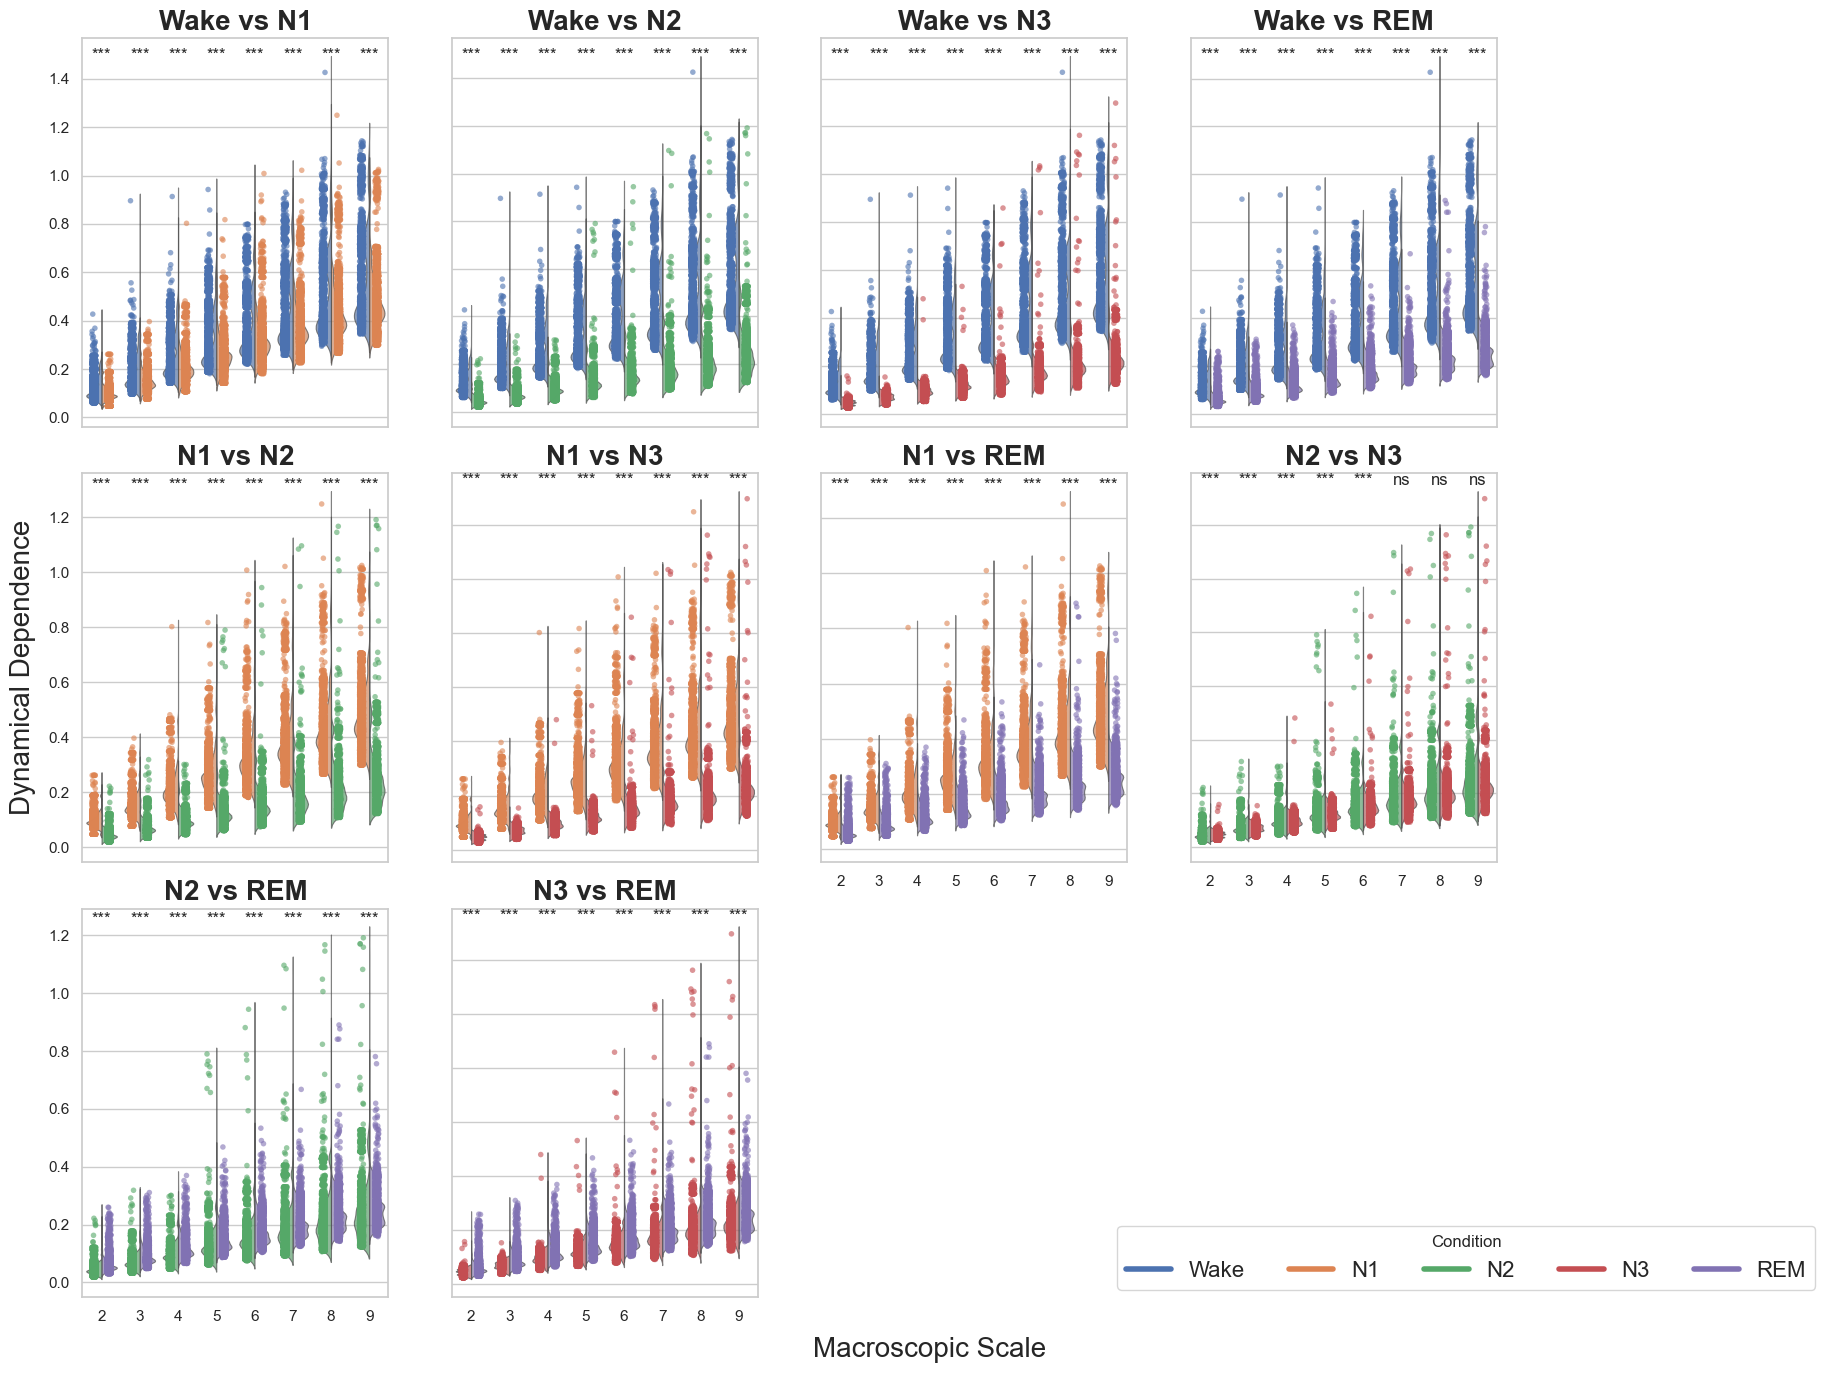

Figure saved successfully in /Users/borjan/code/healthy-sleep-project/code/ssdi_analysis/figs/


In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import os
from statsmodels.stats.multitest import multipletests
from scipy.stats import mannwhitneyu

# Conditions to compare
conditions = ['W_', 'N1', 'N2', 'N3', 'R_']
comparison_labels = {'W_': 'Wake', 'N1': 'N1', 'N2': 'N2', 'N3': 'N3', 'R_': 'REM'}
macros = range(2, 10)

# Generate all unique pairwise comparisons
comparisons = [(cond1, cond2) for i, cond1 in enumerate(conditions) for j, cond2 in enumerate(conditions) if i < j]

# Initialize data structures for plotting
dopto_data = []
condition_labels = []
macro_labels = []
comparison_idx = []
p_values = {comparison: [] for comparison in comparisons}

# Loop through comparisons and collect dopto values
for comparison in comparisons:
    condition_1, condition_2 = comparison
    for macro_size in macros:
        group_1 = [dopto_matrices[condition_1][participant][macro_size].flatten() for participant in participants]
        group_2 = [dopto_matrices[condition_2][participant][macro_size].flatten() for participant in participants]

        # Truncate to minimum matching length
        min_length = min(min(dopto.shape[0] for dopto in group_1), min(dopto.shape[0] for dopto in group_2))
        group_1 = [dopto[:min_length] for dopto in group_1]
        group_2 = [dopto[:min_length] for dopto in group_2]

        # Flatten and collect the data
        dopto_data.extend(group_1 + group_2)
        condition_labels.extend([comparison_labels[condition_1]] * len(group_1) + [comparison_labels[condition_2]] * len(group_2))
        macro_labels.extend([macro_size] * (len(group_1) + len(group_2)))
        comparison_idx.extend([f"{comparison_labels[condition_1]} vs {comparison_labels[condition_2]}"] * (len(group_1) + len(group_2)))

        # Perform MWU test for this macroscopic size
        group_1_combined = np.concatenate(group_1)
        group_2_combined = np.concatenate(group_2)
        _, p_value = mannwhitneyu(group_1_combined, group_2_combined, alternative='two-sided')
        p_values[comparison].append(p_value)

# Apply FDR correction for multiple comparisons
for comparison in comparisons:
    _, p_values_corrected, _, _ = multipletests(p_values[comparison], method='fdr_bh')
    p_values[comparison] = p_values_corrected

# Create a DataFrame for easier plotting with seaborn
dopto_data_flattened = np.concatenate(dopto_data)
data_df = pd.DataFrame({
    'Dopto Values': np.concatenate(dopto_data),
    'Condition': np.repeat(condition_labels, len(dopto_data[0])),
    'Macroscopic Scale': np.repeat(macro_labels, len(dopto_data[0])),
    'Comparison': np.repeat(comparison_idx, len(dopto_data[0]))
})

# Set up the figure size and style
n_comparisons = len(comparisons)
n_rows = (n_comparisons + 3) // 4  # Number of rows for the subplots (4 columns)
fig, axs = plt.subplots(n_rows, 4, figsize=(20, 5 * n_rows))  # Adjust figure size based on number of comparisons
sns.set(style="whitegrid")

# Define color palette to keep Wake the same color, and vary the other conditions
palette = {
    'Wake': 'C0',  # Keep Wake the same color
    'N1': 'C1',    # Unique color for N1
    'N2': 'C2',    # Unique color for N2
    'N3': 'C3',    # Unique color for N3
    'REM': 'C4'    # Unique color for REM
}

# Plot each comparison in a subplot
for i, (ax, comparison) in enumerate(zip(axs.flatten(), comparisons)):
    condition_1, condition_2 = comparison
    comparison_label = f"{comparison_labels[condition_1]} vs {comparison_labels[condition_2]}"
    
    # Filter the data for this comparison
    comparison_data = data_df[data_df['Comparison'] == comparison_label]
    
    # Create a violin plot with transparency and wider violins, adjusting border width
    sns.violinplot(x='Macroscopic Scale', y='Dopto Values', hue='Condition', data=comparison_data, split=True,
                   inner=None, palette=palette, alpha=0.7, scale="width", linewidth=0.8, ax=ax, legend=False)

    # Overlay individual data points without adding them to the legend
    sns.stripplot(x='Macroscopic Scale', y='Dopto Values', hue='Condition', data=comparison_data, dodge=True,
                  jitter=True, marker='o', alpha=0.6, size=4, palette=palette, edgecolor="gray", ax=ax, legend=False)

    # Add significance annotations (corrected p-values)
    for j, p_val_corrected in enumerate(p_values[comparison]):
        macro_size = macros[j]
        if p_val_corrected < 0.001:
            significance = '***'
        elif p_val_corrected < 0.01:
            significance = '**'
        elif p_val_corrected < 0.05:
            significance = '*'
        else:
            significance = 'ns'  # Not significant

        # Place the annotation in the middle of the plot for each macroscopic size
        ax.text(j, np.max(comparison_data['Dopto Values']) + 0.05, significance, ha='center', fontsize=12)
    
    # Remove x-tick labels except for the last row and plots in position (2,3) and (2,4)
    if (i // 4 != n_rows - 1) and not (i in [6, 7]):
        ax.set_xticklabels([])

    # Remove y-tick labels except for the first column
    if i % 4 != 0:
        ax.set_yticklabels([])

    # Remove individual x and y axis labels
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.set_title(comparison_label, fontsize=20, fontweight='bold')

# Turn off empty subplots
for ax in axs.flatten()[n_comparisons:]:
    ax.axis('off')

# Create the custom grand legend manually
from matplotlib.lines import Line2D

custom_lines = [
    Line2D([0], [0], color='C0', lw=4, label='Wake'),
    Line2D([0], [0], color='C1', lw=4, label='N1'),
    Line2D([0], [0], color='C2', lw=4, label='N2'),
    Line2D([0], [0], color='C3', lw=4, label='N3'),
    Line2D([0], [0], color='C4', lw=4, label='REM')
]

# Place the grand legend in the empty (3,3) position
plt.legend(handles=custom_lines, loc='center', bbox_to_anchor=(0.9, 0.1), ncol=5, fontsize=16, title="Condition")

# Add a global x-axis label and y-axis label
fig.text(0.5, 0.04, 'Macroscopic Scale', ha='center', fontsize=20)
fig.text(0.04, 0.5, 'Dynamical Dependence', va='center', rotation='vertical', fontsize=20)

# Adjust the layout to prevent overlap and optimize space
plt.tight_layout(rect=[0.05, 0.05, 0.95, 0.95])

# Define the directory where the figure will be saved
save_dir = "/Users/borjan/code/healthy-sleep-project/code/ssdi_analysis/figs/"

# Check if the directory exists, if not, create it
if not os.path.exists(save_dir):
    os.makedirs(save_dir)
    print(f"Directory {save_dir} created.")

# Save the figure as an SVG file
svg_filename = os.path.join(save_dir, "dopto_comparisons_across_macroscopic_sizes_all_pairs_clean.svg")
plt.savefig(svg_filename, format='svg')

# Show the plot
plt.show()

print(f"Figure saved successfully in {save_dir}")


/var/folders/yy/z6qg2k8n2h3g714cbbr9xp040000gn/T/ipykernel_81839/2566067871.py:88: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(x='Macroscopic Scale', y='Dopto Values', hue='Condition', data=comparison_data, split=True,
/var/folders/yy/z6qg2k8n2h3g714cbbr9xp040000gn/T/ipykernel_81839/2566067871.py:92: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(x='Macroscopic Scale', y='Dopto Values', hue='Condition', data=comparison_data, dodge=True,
/var/folders/yy/z6qg2k8n2h3g714cbbr9xp040000gn/T/ipykernel_81839/2566067871.py:88: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(x='Macroscopic Scale', y='Dopto Values', hue='Condition', data=comparison_data, split=True,
/var/folders/yy/z6qg2k8n2h3g

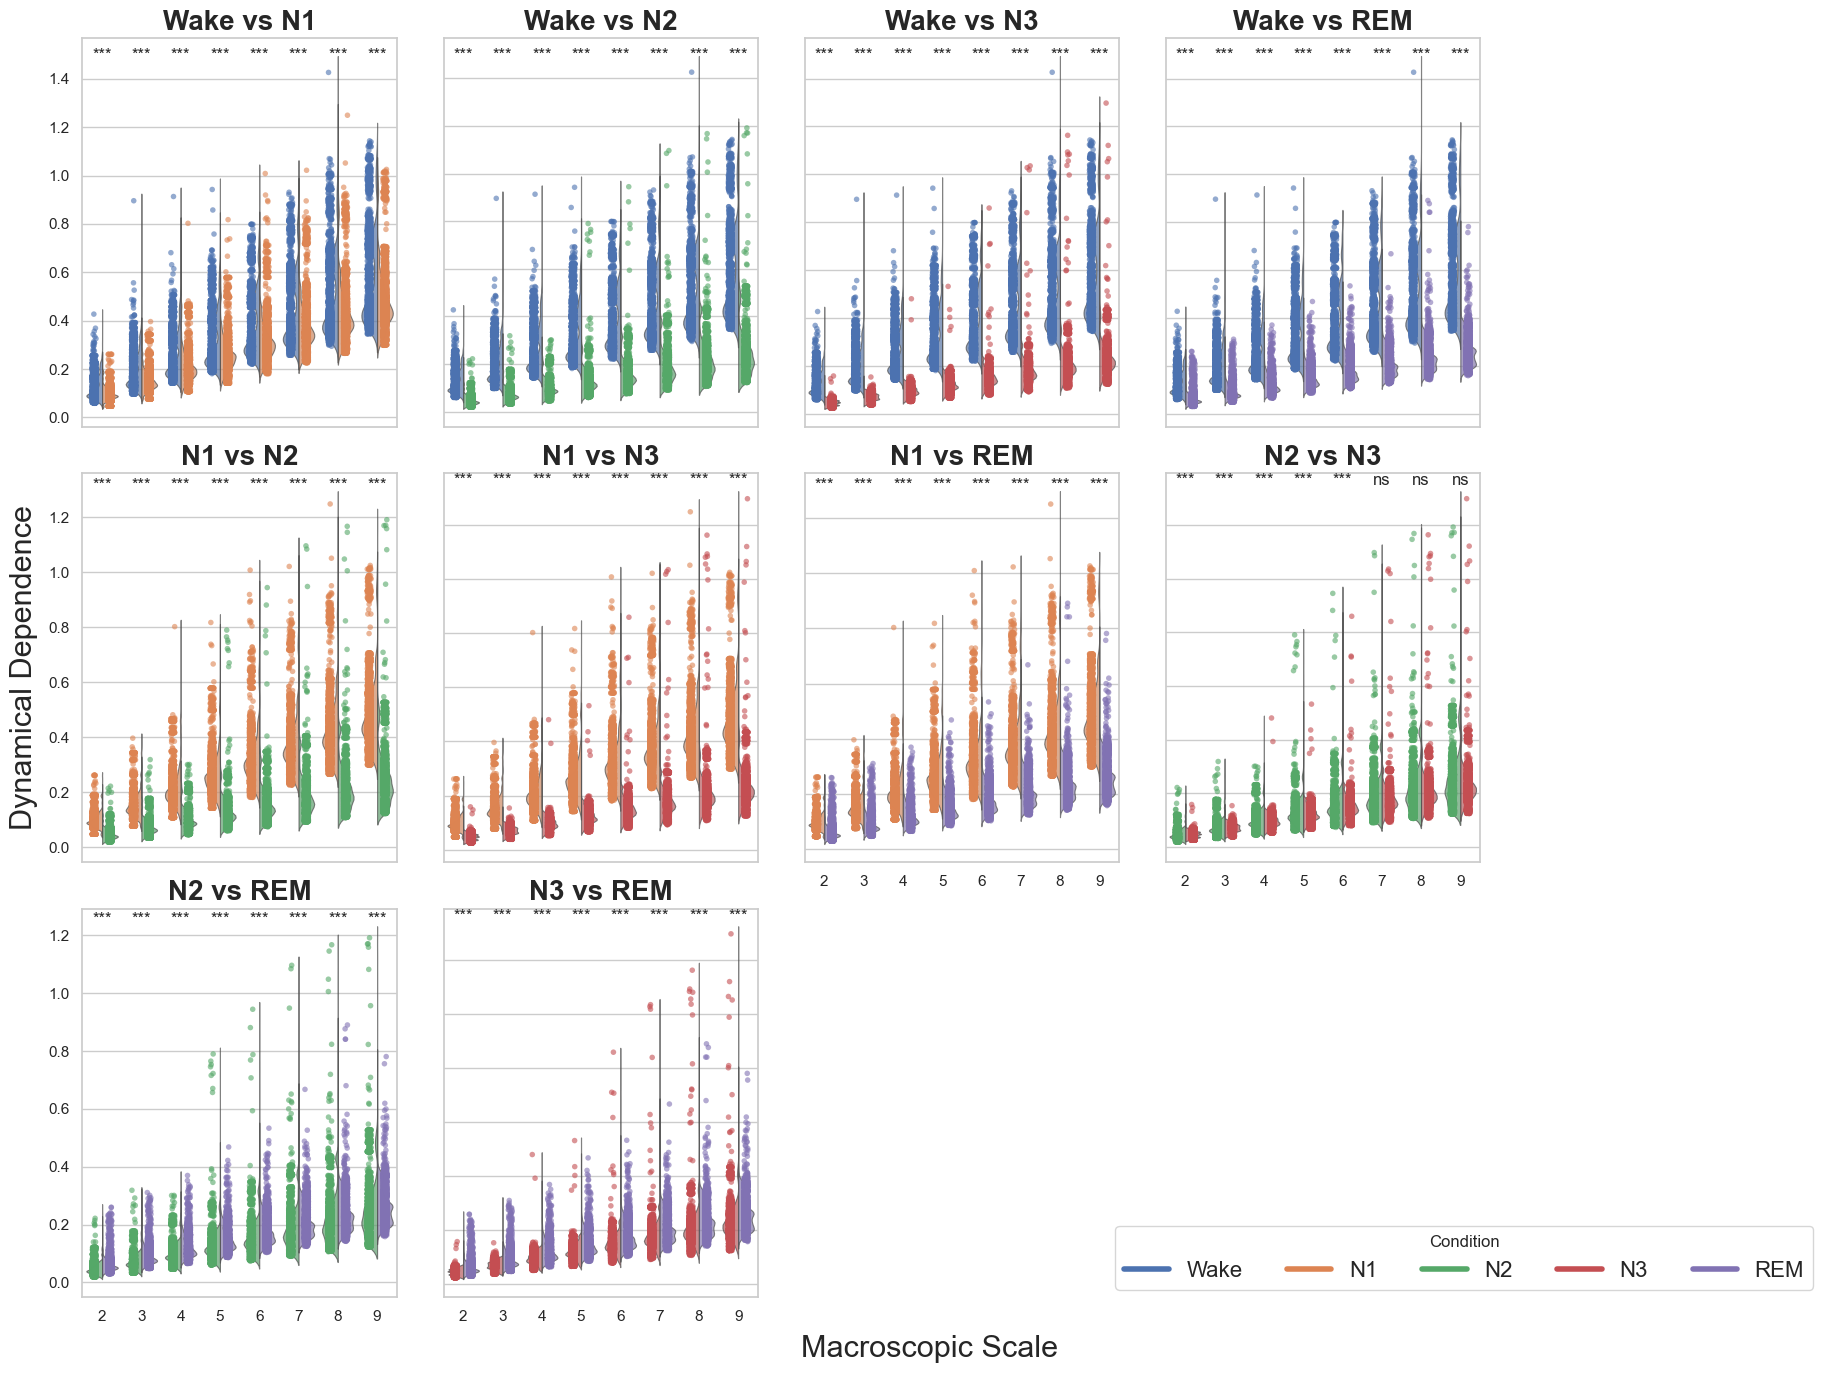

Figure saved successfully in /Users/borjan/code/healthy-sleep-project/code/ssdi_analysis/figs/


In [16]:
#### PNG SAVING

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import os
from statsmodels.stats.multitest import multipletests
from scipy.stats import mannwhitneyu

# Conditions to compare
conditions = ['W_', 'N1', 'N2', 'N3', 'R_']
comparison_labels = {'W_': 'Wake', 'N1': 'N1', 'N2': 'N2', 'N3': 'N3', 'R_': 'REM'}
macros = range(2, 10)

# Generate all unique pairwise comparisons
comparisons = [(cond1, cond2) for i, cond1 in enumerate(conditions) for j, cond2 in enumerate(conditions) if i < j]

# Initialize data structures for plotting
dopto_data = []
condition_labels = []
macro_labels = []
comparison_idx = []
p_values = {comparison: [] for comparison in comparisons}

# Loop through comparisons and collect dopto values
for comparison in comparisons:
    condition_1, condition_2 = comparison
    for macro_size in macros:
        group_1 = [dopto_matrices[condition_1][participant][macro_size].flatten() for participant in participants]
        group_2 = [dopto_matrices[condition_2][participant][macro_size].flatten() for participant in participants]

        # Truncate to minimum matching length
        min_length = min(min(dopto.shape[0] for dopto in group_1), min(dopto.shape[0] for dopto in group_2))
        group_1 = [dopto[:min_length] for dopto in group_1]
        group_2 = [dopto[:min_length] for dopto in group_2]

        # Flatten and collect the data
        dopto_data.extend(group_1 + group_2)
        condition_labels.extend([comparison_labels[condition_1]] * len(group_1) + [comparison_labels[condition_2]] * len(group_2))
        macro_labels.extend([macro_size] * (len(group_1) + len(group_2)))
        comparison_idx.extend([f"{comparison_labels[condition_1]} vs {comparison_labels[condition_2]}"] * (len(group_1) + len(group_2)))

        # Perform MWU test for this macroscopic size
        group_1_combined = np.concatenate(group_1)
        group_2_combined = np.concatenate(group_2)
        _, p_value = mannwhitneyu(group_1_combined, group_2_combined, alternative='two-sided')
        p_values[comparison].append(p_value)

# Apply FDR correction for multiple comparisons
for comparison in comparisons:
    _, p_values_corrected, _, _ = multipletests(p_values[comparison], method='fdr_bh')
    p_values[comparison] = p_values_corrected

# Create a DataFrame for easier plotting with seaborn
dopto_data_flattened = np.concatenate(dopto_data)
data_df = pd.DataFrame({
    'Dopto Values': np.concatenate(dopto_data),
    'Condition': np.repeat(condition_labels, len(dopto_data[0])),
    'Macroscopic Scale': np.repeat(macro_labels, len(dopto_data[0])),
    'Comparison': np.repeat(comparison_idx, len(dopto_data[0]))
})

# Set up the figure size and style
n_comparisons = len(comparisons)
n_rows = (n_comparisons + 3) // 4  # Number of rows for the subplots (4 columns)
fig, axs = plt.subplots(n_rows, 4, figsize=(20, 5 * n_rows))  # Adjust figure size based on number of comparisons
sns.set(style="whitegrid")

# Define color palette to keep Wake the same color, and vary the other conditions
palette = {
    'Wake': 'C0',  # Keep Wake the same color
    'N1': 'C1',    # Unique color for N1
    'N2': 'C2',    # Unique color for N2
    'N3': 'C3',    # Unique color for N3
    'REM': 'C4'    # Unique color for REM
}

# Plot each comparison in a subplot
for i, (ax, comparison) in enumerate(zip(axs.flatten(), comparisons)):
    condition_1, condition_2 = comparison
    comparison_label = f"{comparison_labels[condition_1]} vs {comparison_labels[condition_2]}"
    
    # Filter the data for this comparison
    comparison_data = data_df[data_df['Comparison'] == comparison_label]
    
    # Create a violin plot with transparency and wider violins, adjusting border width
    sns.violinplot(x='Macroscopic Scale', y='Dopto Values', hue='Condition', data=comparison_data, split=True,
                   inner=None, palette=palette, alpha=0.7, scale="width", linewidth=0.8, ax=ax, legend=False)

    # Overlay individual data points without adding them to the legend
    sns.stripplot(x='Macroscopic Scale', y='Dopto Values', hue='Condition', data=comparison_data, dodge=True,
                  jitter=True, marker='o', alpha=0.6, size=4, palette=palette, edgecolor="gray", ax=ax, legend=False)

    # Add significance annotations (corrected p-values)
    for j, p_val_corrected in enumerate(p_values[comparison]):
        macro_size = macros[j]
        if p_val_corrected < 0.001:
            significance = '***'
        elif p_val_corrected < 0.01:
            significance = '**'
        elif p_val_corrected < 0.05:
            significance = '*'
        else:
            significance = 'ns'  # Not significant

        # Place the annotation in the middle of the plot for each macroscopic size
        ax.text(j, np.max(comparison_data['Dopto Values']) + 0.05, significance, ha='center', fontsize=12)
    
    # Remove x-tick labels except for the last row and plots in position (2,3) and (2,4)
    if (i // 4 != n_rows - 1) and not (i in [6, 7]):
        ax.set_xticklabels([])

    # Remove y-tick labels except for the first column
    if i % 4 != 0:
        ax.set_yticklabels([])

    # Remove individual x and y axis labels
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.set_title(comparison_label, fontsize=20, fontweight='bold')

# Turn off empty subplots
for ax in axs.flatten()[n_comparisons:]:
    ax.axis('off')

# Create the custom grand legend manually
from matplotlib.lines import Line2D

custom_lines = [
    Line2D([0], [0], color='C0', lw=4, label='Wake'),
    Line2D([0], [0], color='C1', lw=4, label='N1'),
    Line2D([0], [0], color='C2', lw=4, label='N2'),
    Line2D([0], [0], color='C3', lw=4, label='N3'),
    Line2D([0], [0], color='C4', lw=4, label='REM')
]

# Place the grand legend in the empty (3,3) position
plt.legend(handles=custom_lines, loc='center', bbox_to_anchor=(0.95, 0.1), ncol=5, fontsize=16, title="Condition")

# Add a global x-axis label and y-axis label
fig.text(0.5, 0.04, 'Macroscopic Scale', ha='center', fontsize=22)
fig.text(0.04, 0.5, 'Dynamical Dependence', va='center', rotation='vertical', fontsize=22)

# Adjust the layout to prevent overlap and optimize space
plt.tight_layout(rect=[0.05, 0.05, 0.95, 0.95])

# Define the directory where the figure will be saved
save_dir = "/Users/borjan/code/healthy-sleep-project/code/ssdi_analysis/figs/"

# Check if the directory exists, if not, create it
if not os.path.exists(save_dir):
    os.makedirs(save_dir)
    print(f"Directory {save_dir} created.")

# Save the figure as PNG (for smaller file size)
png_filename = os.path.join(save_dir, "dopto_comparisons_across_macroscopic_sizes_all_pairs_clean.png")
plt.savefig(png_filename, format='png', dpi=300)  # Higher DPI for better resolution

# Show the plot
plt.show()

print(f"Figure saved successfully in {save_dir}")


In [17]:
import ot
import numpy as np
from pathos.multiprocessing import ProcessingPool as Pool

# Define the function to compute Gromov-Wasserstein distance
def compute_gromov_wasserstein(matrix1, matrix2):
    p = ot.unif(matrix1.shape[0])  # Uniform distribution for matrix1
    q = ot.unif(matrix2.shape[0])  # Uniform distribution for matrix2
    gw_dist = ot.gromov.gromov_wasserstein2(matrix1, matrix2, p, q, loss_fun='square_loss')
    return gw_dist

# Define the parallel computation function
def compute_gw_distance_parallel(args):
    cond1, cond2, participant, macro_size, matrix1, matrix2 = args
    gw_distance = compute_gromov_wasserstein(matrix1, matrix2)
    return (cond1, cond2, participant, macro_size, gw_distance)

if __name__ == '__main__':
    # Conditions and participants
    conditions = ['W_', 'N1', 'N2', 'N3', 'R_']
    participants = [f"{i:02d}" for i in range(1, 30)]  # Participants 01 to 29
    macros = range(2, 10)  # Macroscopic sizes 2 to 9

    # Prepare the list of tasks (comparisons) for parallel execution
    tasks = []
    for participant in participants:
        for macro_size in macros:
            for cond1 in conditions:
                for cond2 in conditions:
                    if cond1 != cond2:
                        matrix1 = opt_similarity_matrices[cond1][participant][macro_size]
                        matrix2 = opt_similarity_matrices[cond2][participant][macro_size]
                        tasks.append((cond1, cond2, participant, macro_size, matrix1, matrix2))

    # Use pathos multiprocessing Pool to compute GW distances in parallel
    pool = Pool()
    results = pool.map(compute_gw_distance_parallel, tasks)

    # Reorganize the results back into the gw_distances structure
    gw_distances = {cond: {other_cond: {macro_size: [] for macro_size in macros} for other_cond in conditions} for cond in conditions}

    for cond1, cond2, participant, macro_size, gw_distance in results:
        gw_distances[cond1][cond2][macro_size].append(gw_distance)

    # Now you have GW distances computed in parallel for all conditions, participants, and macroscopic sizes


In [18]:
import numpy as np
import os

# Define the directory where the results will be saved
save_dir = "/Users/borjan/code/healthy-sleep-project/code/ssdi_analysis/data/"

# Check if the directory exists, if not, create it
if not os.path.exists(save_dir):
    os.makedirs(save_dir)
    print(f"Directory {save_dir} created.")

# Save the GW distances to a compressed .npz file
np.savez_compressed(os.path.join(save_dir, 'gw_distances_new.npz'), **gw_distances)

print(f"GW distances saved successfully in {save_dir}")


GW distances saved successfully in /Users/borjan/code/healthy-sleep-project/code/ssdi_analysis/data/


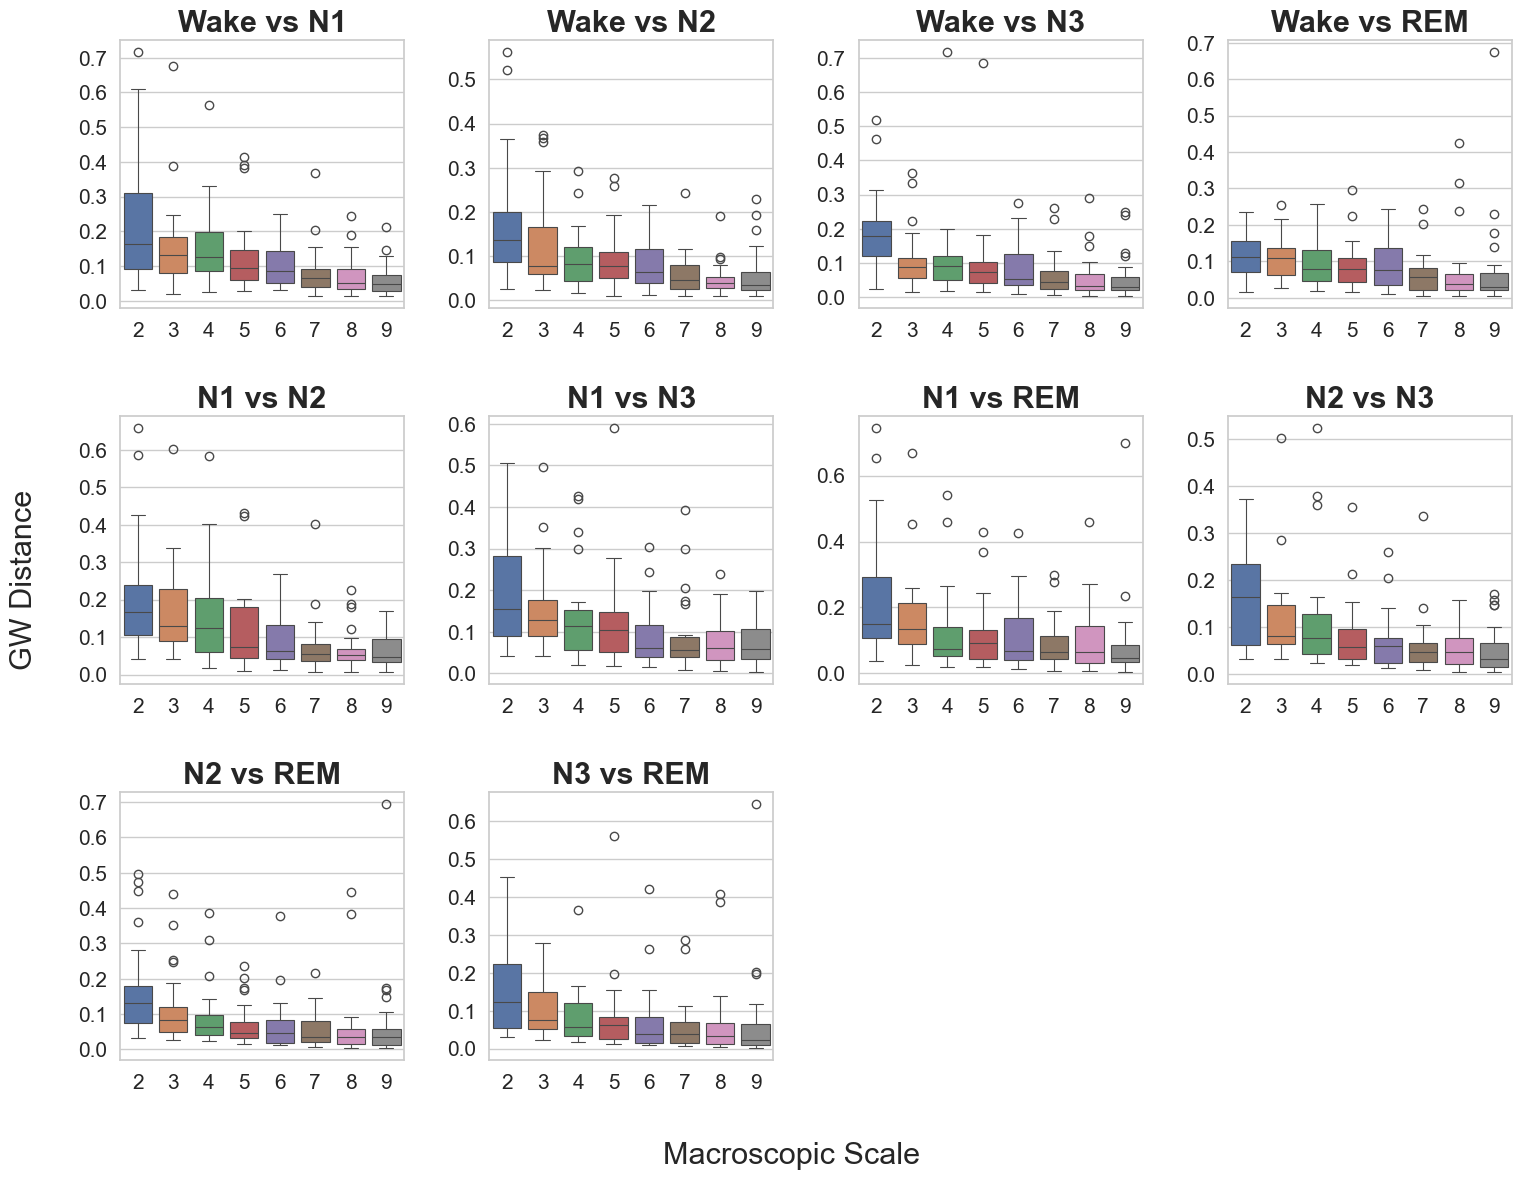

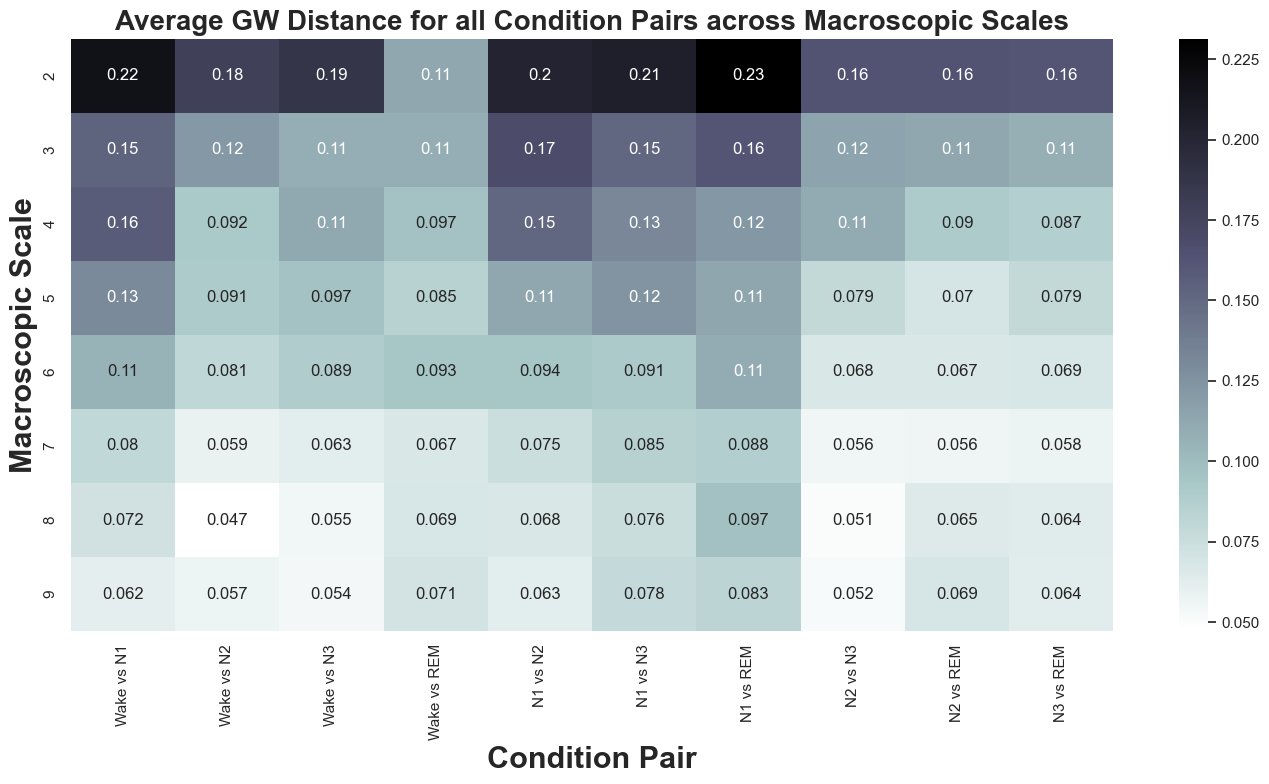

Figures saved successfully in /Users/borjan/code/healthy-sleep-project/code/results/ssdi_analysis/figs/


In [22]:
from scipy.stats import mannwhitneyu, kruskal
from statsmodels.stats.multitest import multipletests
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os

# Directory to save the figures
save_dir = "/Users/borjan/code/healthy-sleep-project/code/results/ssdi_analysis/figs/"
if not os.path.exists(save_dir):
    os.makedirs(save_dir)

# Set Seaborn aesthetic style
sns.set(style="whitegrid")

# Define conditions and macroscopic sizes
conditions = ['W_', 'N1', 'N2', 'N3', 'R_']
condition_labels = {'W_': 'Wake', 'R_': 'REM'}
macros = range(2, 10)

# Create condition pairs for statistical testing and plotting
condition_pairs = [(cond1, cond2) for i, cond1 in enumerate(conditions) for j, cond2 in enumerate(conditions) if i < j]

# Initialize variables to store MWU p-values for FDR correction
p_values_mwu = []

# Perform pairwise Mann-Whitney U tests across condition pairs for each macroscopic size
for macro_size in macros:
    for i, cond1 in enumerate(conditions):
        for j, cond2 in enumerate(conditions):
            if i < j:
                # MWU Test between condition pairs for the current macroscopic size
                group1 = gw_distances[cond1][cond2][macro_size]
                group2 = gw_distances[cond2][cond1][macro_size]
                stat, p_value = mannwhitneyu(group1, group2)
                p_values_mwu.append((macro_size, cond1, cond2, p_value))

# Extract just the p-values to apply FDR correction for MWU
p_vals_only_mwu = [p[3] for p in p_values_mwu]

# Apply FDR correction for MWU results
_, p_vals_corrected_mwu, _, _ = multipletests(p_vals_only_mwu, method='fdr_bh')

# Reshape the corrected MWU p-values into a matrix for heatmap plotting
significance_matrix_mwu = np.zeros((len(macros), len(condition_pairs)))
idx = 0
for k, corrected_p in enumerate(p_vals_corrected_mwu):
    macro_size, cond1, cond2, _ = p_values_mwu[k]
    if corrected_p < 0.05:
        significance_matrix_mwu[macro_size - 2, idx] = 1  # Significant results (FDR-corrected)
    idx += 1

# First figure: Boxplots for each condition pair across macroscopic sizes
plt.figure(figsize=(16, 12))  # Adjust figure size based on the number of comparisons
for idx, (cond1, cond2) in enumerate(condition_pairs):
    gw_distances_combined = []
    for macro_size in macros:
        gw_distances_combined.append(gw_distances[cond1][cond2][macro_size])

    ax = plt.subplot(3, 4, idx + 1)
    sns.boxplot(data=gw_distances_combined, linewidth=0.8, showfliers=True)

    # Replace W_ with Wake and R_ with REM in the titles
    title_cond1 = condition_labels.get(cond1, cond1)
    title_cond2 = condition_labels.get(cond2, cond2)
    plt.title(f'{title_cond1} vs {title_cond2}', fontsize=22, fontweight='bold')

    # Set x-axis tick labels to go from 2 to 9
    ax.set_xticks(range(8))
    ax.set_xticklabels(range(2, 10))

    # Increase font size for x and y tick labels
    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)

    # Remove individual axis labels
    plt.xlabel('')
    plt.ylabel('')

# Add one big x-axis label for the entire figure
plt.text(0.5, 0.02, 'Macroscopic Scale', ha='center', va='center', fontsize=22, transform=plt.gcf().transFigure)
plt.text(0.02, 0.5, 'GW Distance', ha='center', va='center', rotation='vertical', fontsize=22, transform=plt.gcf().transFigure)
plt.subplots_adjust(left=0.08, bottom=0.1, right=0.95, top=0.95, wspace=0.3, hspace=0.4)

# Save and show the first figure (Boxplots)
plt.savefig(os.path.join(save_dir, 'gw_distance_comparisons_boxplots.svg'), format='svg')


# Save the figure as PNG (for smaller file size)
png_filename = os.path.join(save_dir, "ddw_distance_comparisons_boxplots.png")
plt.savefig(png_filename, format='png', dpi=300)  # Higher DPI for better resolution

plt.show()

# Second figure: Heatmap for average GW distances

# Organize data into a 2D matrix (macroscopic size x condition pair)
heatmap_data = np.zeros((len(macros), len(conditions) * (len(conditions) - 1) // 2))

# Fill the heatmap data
idx = 0
for i, cond1 in enumerate(conditions):
    for j, cond2 in enumerate(conditions):
        if i < j:  # Only consider unique pairs, e.g., Wake vs N1, N1 vs N2, etc.
            for macro_size in macros:
                avg_gw_distance = np.mean(gw_distances[cond1][cond2][macro_size])
                heatmap_data[macro_size - 2, idx] = avg_gw_distance
            idx += 1

# Create condition labels for the x-axis
condition_pairs_heatmap = [f"{condition_labels.get(cond1, cond1)} vs {condition_labels.get(cond2, cond2)}" for i, cond1 in enumerate(conditions) for j, cond2 in enumerate(conditions) if i < j]

# Visualize as a heatmap
plt.figure(figsize=(14, 8))
sns.heatmap(heatmap_data, annot=True, cmap="bone_r", xticklabels=condition_pairs_heatmap, yticklabels=macros)
plt.title('Average GW Distance for all Condition Pairs across Macroscopic Scales', fontsize=20, fontweight='bold')
plt.xlabel('Condition Pair', fontsize=22, fontweight='bold')
plt.ylabel('Macroscopic Scale', fontsize=22, fontweight='bold')
plt.tight_layout()

# Save and show the second figure (Heatmap)
plt.savefig(os.path.join(save_dir, 'gw_distance_heatmap.svg'), format='svg')


# Save the figure as PNG (for smaller file size)
png_filename = os.path.join(save_dir, "gw_distance_heatmap.png")
plt.savefig(png_filename, format='png', dpi=300)  # Higher DPI for better resolution

plt.show()


print(f"Figures saved successfully in {save_dir}")


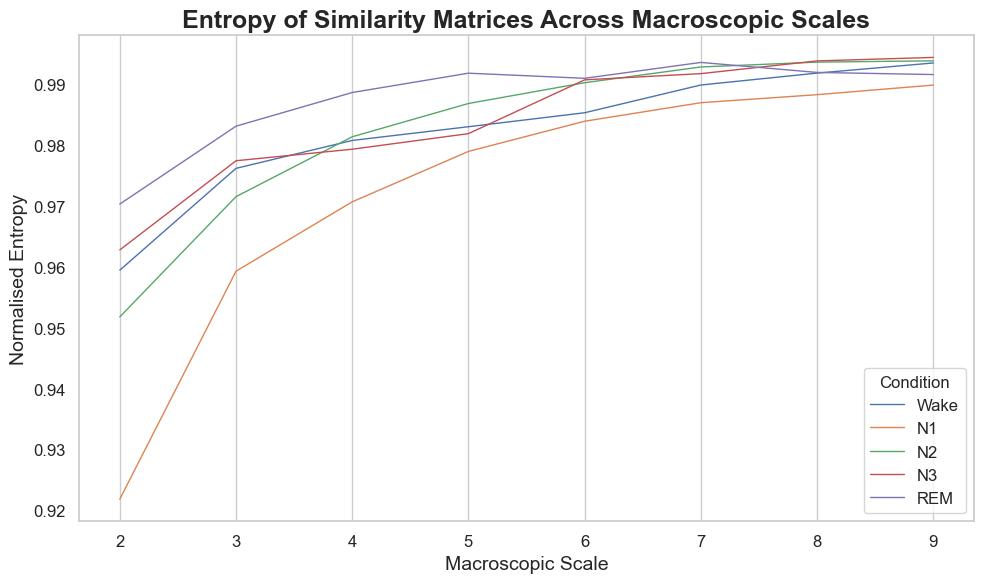

Figure saved successfully in /Users/borjan/code/healthy-sleep-project/code/results/ssdi_analysis/figs/


In [167]:
import numpy as np
from scipy.stats import entropy
import seaborn as sns
import matplotlib.pyplot as plt

def compute_normalized_entropy(matrix):
    """
    Computes the normalized entropy of a matrix.
    """
    # Flatten the matrix into a 1D array and normalize the values to form a probability distribution
    flattened_matrix = matrix.flatten()
    normalized_matrix = flattened_matrix / np.sum(flattened_matrix)  # Convert to probability distribution
    
    # Compute entropy and normalize it by dividing by log of the matrix size
    matrix_entropy = entropy(normalized_matrix)
    max_entropy = np.log(len(flattened_matrix))  # Maximum possible entropy for this matrix size
    normalized_entropy = matrix_entropy / max_entropy  # Normalize entropy to be between 0 and 1
    
    return normalized_entropy

# Initialize a structure to store normalized entropy values
entropy_values = {cond: {macro_size: [] for macro_size in macros} for cond in conditions}

# Compute the normalized entropy for each condition, participant, and macroscopic size
for condition in conditions:
    for participant in participants:
        for macro_size in macros:
            matrix = opt_similarity_matrices[condition][participant][macro_size]
            entropy_value = compute_normalized_entropy(matrix)
            entropy_values[condition][macro_size].append(entropy_value)

# Prepare data for plotting: average entropy for each condition across macroscopic sizes
average_entropy = {cond: [np.mean(entropy_values[cond][macro_size]) for macro_size in macros] for cond in conditions}

# Replace W_ with Wake and R_ with REM for legend labels
legend_labels = {'W_': 'Wake', 'R_': 'REM'}
conditions_labels = [legend_labels.get(cond, cond) for cond in conditions]  # Replace for legend

# Plotting the average normalized entropy across macroscopic sizes
plt.figure(figsize=(10, 6))

# Plot with reduced line width
for condition, label in zip(conditions, conditions_labels):
    plt.plot(macros, average_entropy[condition], label=label, linewidth=1)  # Decrease line width

# Customize plot aesthetics
plt.title('Entropy of Similarity Matrices Across Macroscopic Scales', fontsize=22, fontweight='bold')  # Increased title size
plt.xlabel('Macroscopic Scale', fontsize=14)  # Increase x-axis label font size
plt.ylabel('Normalised Entropy', fontsize=14)  # Increase y-axis label font size
plt.legend(title="Condition", fontsize=12)  # Increase legend font size
plt.xticks(fontsize=12)  # Increase tick labels' font size
plt.yticks(fontsize=12)  # Increase tick labels' font size

# Enable vertical grid lines only
plt.grid(True, axis='x')
plt.grid(False, axis='y')

plt.tight_layout()

# Save the figure
save_dir = "/Users/borjan/code/healthy-sleep-project/code/results/ssdi_analysis/figs/"
plt.savefig(os.path.join(save_dir, 'average_entropy_plot.svg'), format='svg')

# Save the figure as PNG (for smaller file size)
png_filename = os.path.join(save_dir, "entropy_of_similarity_matrices.png")
plt.savefig(png_filename, format='png', dpi=300)  # Higher DPI for better resolution

# Show the plot
plt.show()

print(f"Figure saved successfully in {save_dir}")
